# Technique detection: finding toots, tongue stops, trills and more in a recording

`didgelab.synth.transcribe` listens to a didgeridoo recording and writes down which playing techniques the
player used. This notebook explains

1. **Introduction**: what the detector looks for and how it learned it
2. **Maths**: the lip frequency on the bore resonances, the formant and the tongue index, the learned
   detector and how it is evaluated
3. **Code examples**: a synthetic performance with a known score, a real recording of the Didge Archive and
   the stored evaluation

The method is described in [synthesizer.md](../synthesizer.md), sections 8 and 9.

## 1. Introduction

When you play the didgeridoo you do several things at once. Your **lips** buzz on one of the resonances of
the instrument: the lowest one is the drone, a higher one is a toot. Your **tongue** moves front and back
("ee" ... "oo") and changes the colour of the sound. It also taps the roof of the mouth for stop consonants:
*t* and *d* with the tip of the tongue at the front, *k* and *g* with the back of the tongue. A **rolled r**
makes the tongue tip flutter. You can **sing** into the instrument (vocalisation). And during **circular
breathing** you close the mouth with the back of the tongue, push air out with the cheeks and sniff in
through the nose.

The detector tries to find all of this in a recording. It works in three steps.

**Which resonance do the lips play?** The lips of a didgeridoo player always lock to a resonance of the
bore. DidgeLab can compute these resonances from the measured shape. So the detector does not search for the
pitch everywhere. It only checks the few places where the lips *can* play. If the sound sits on the second
resonance, it is a toot.

**Where is the tongue?** The mouth acts like a filter. With the tongue in front you hear a bright line high
up in the spectrum (around 2.5–3 kHz). With the tongue at the back this line moves down to about 1 kHz. This
line is called the *formant*. The detector follows it frame by frame and translates it into a **tongue
index**: 0 = front, 1 = back.

**What else happens?** Stops, trills, singing, circular breaths and fricatives (*h*, *ch*, *s*) are found by
a learned model. The trick: the model has **never heard a real recording**. The synthesizer of DidgeLab
plays thousands of random but idiomatic grooves on random didgeridoos. Because we wrote the scores, we know
exactly when each technique happens. The model learns from these examples. It is then tested on the eight
real geometries of the Didge Archive, which it has never seen.

If the trained model is not available, `transcribe` uses a simpler rule-based detector instead (it looks for
dips in the loudness, wobbling of the loudness, energy between the harmonics, ...). The code below prints
which one was used. The model file is `src/didgelab/synth/data/detector.joblib`; it is created by
`python scripts/synth/train_detector.py`.

A word of caution: on real recordings the results are **hypotheses**. The detector knows the techniques as
the synthesizer plays them. Real players do them differently, and there are no hand-made annotations of the
archive recordings yet.

## 2. Maths

The recording is resampled to 48 kHz and cut into frames with a hop of 10 ms (a short-time Fourier
transform, window 4096 samples, FFT size 8192). $L_t(f)$ is the log magnitude spectrum (dB) of frame $t$.

### 2.1 Lip frequency constrained to the bore resonances

$f_1 < f_2 < \dots < f_6$ are the first six impedance peaks of the bore, computed with DidgeLab ($f_1$ is the
drone). The score of a lip frequency candidate $f$ is the mean level of its first 12 harmonics relative to
the mean level $\overline{L_t}$ of the frame (30 Hz – 3 kHz):

$$
s_t(f) = \frac{1}{12}\sum_{n=1}^{12} L_t(nf) - \overline{L_t},
\qquad
\hat s_{t,k} = \max_{|1200\log_2(f/f_k)|\le 90} s_t(f).
$$

The candidates are searched in 5-cent steps within $\pm 90$ cents around each resonance. The lips play on
the **lowest** resonance whose score is within 4 dB of the best one,

$$
k^{\ast}_t = \min\lbrace k : \hat s_{t,k} \ge \max_j \hat s_{t,j} - 4\,\text{dB}\rbrace .
$$

$k^\ast = 1$ is the drone, $k^\ast = 2$ the first toot, and so on (in the code `mode` $= k^\ast - 1$, so
`toot1` is the 2nd resonance). Preferring the lowest resonance prevents octave errors: a toot is only
accepted if the harmonics of the drone in between are clearly weaker. Frames are *voiced* if a generic
pitch tracker finds a pitch there or the frame level is within 30 dB of the loudest frame.

### 2.2 Formant and tongue index

For each frame the spectral envelope $E_t(f)$ is the maximum of $L_t$ over $\pm 40$ Hz (this bridges the gaps
between the harmonics), averaged over 250 Hz. It is compared with the median envelope of the whole recording,
and level and tilt are removed with an affine fit $\alpha_t + \beta_t \log_2 f$:

$$
R_t(f) = E_t(f) - \mathrm{median}_{t'} E_{t'}(f) - \alpha_t - \beta_t\log_2 f,
\qquad
F_t = \arg\max_{500\le f\le 4000} R_t(f).
$$

(If a lower peak of $R_t$ is within 4 dB of the highest one, the lower peak is taken.) $F_t$ is the formant
of frame $t$; it is accepted only if its prominence $R_t(F_t) - \mathrm{median}_f R_t(f)$ exceeds 4 dB.

The vocal-tract model then translates the formant into a tongue position. For the bore at hand the model
formant $F_{\text{model}}(\tau)$ is computed along the tongue-position axis $\tau \in [0.4, 0.95]$, where it
falls monotonically from front to back. The tongue index is

$$
\text{tongue}_t = \frac{F_{\text{model}}^{-1}(F_t) - 0.4}{0.55} \in [0, 1]
\qquad (0 = \text{front},\; 1 = \text{back}),
$$

interpolated in $\log_2 f$ and extrapolated linearly in $\log_2 f$ outside the model range (clipped to
$[-0.25, 1.25]$).

### 2.3 Learned detector

**Training data.** Random scores (cells such as `di ga`, `ti ka`, `rr`, `*too`, `~oo@E3`, pauses, a
circular breath `^` every 2–5 s) are played by random players (open quotient, source impedance, closure
depth and duration, trill rate, base vowel, breath noise, pitch offset) on random bores (length 1.15–1.8 m,
mouthpiece 28–34 mm, bell 55–100 mm, random bulges). They are "recorded" with random room, microphone tilt
($\pm 3$ dB/octave), background noise (SNR 30–55 dB) and gain. Every 10 ms frame gets the exact labels of
the gestures that are active.

**Features** $\mathbf{x}_t$ per frame: level, its derivatives and its deviation from a running median, lip
mode and pitch deviation from the resonance (cents), inharmonic energy, non-harmonic noise at 2–6 kHz,
amplitude modulation depth and rate (15–45 Hz), nine band energies and their derivatives, formant,
prominence and tongue index, and the inverted vocal tract. They are stacked with the frames at offsets
$\pm 1, 3, 5, 10$ (i.e. $\pm 100$ ms) plus mean and standard deviation over 31 frames.

**Model.** One gradient-boosted tree ensemble per class $c \in$ {stop front, stop back, trill, voice,
circular breath, fricative} gives a probability $p_c(t)$. A stop is reported for every run of

$$
p_{\text{front}}(t) + p_{\text{back}}(t) > 0.5
$$

(runs longer than 120 ms are split at maxima at least 100 ms apart); its place of articulation is the larger
of the two probabilities. Trill, voice, circular breath and fricative are runs of $p_c(t) > 0.5$ (after a
70 ms median filter) with a minimum length of 80, 150, 100 and 40 ms. Events are only allowed in frames where
the instrument sounds (lip mode found, level within 35 dB of the maximum).

**Plausibility checks** (applied by `transcribe`): a vocalisation must show sum and difference tones
$n f_0 \pm f_v$ between the harmonics: the strongest non-harmonic peak ($|f/f_0 - \mathrm{round}(f/f_0)| >
0.2$, below 1.5 kHz) must be within 20 dB of the strongest partial. A trill must show an amplitude
modulation of at least 1.5 dB in the 15–45 Hz band.

### 2.4 Rule-based fallback

Without a trained model, `detect.detect` uses simple rules. Toots are runs of $k^\ast \ge 2$ longer than
80 ms. A stop is a dip of the level $\ell_t$ below its running median over 250 ms,

$$
d_t = \mathrm{median}_{250\,\text{ms}}(\ell)_t - \ell_t \ge 4\ \text{dB}, \qquad \text{width} \le 90\ \text{ms},
$$

labelled *t*/*k* if $d_t \ge 9$ dB and *d*/*g* otherwise; front (*t*, *d*) vs back (*k*, *g*) comes from the
tongue position of the vocal-tract inversion (split at 0.45). Trills are amplitude modulations deeper than
2.5 dB, vocalisation an inharmonic energy ratio above 0.22, circular breathing a sealed-mouth configuration
of the inversion or a rise of the high-band noise.

### 2.5 Evaluation

A detected stop is correct if its centre is within $\pm 60$ ms of the centre of a true stop; the other
techniques are correct if they overlap a true event (touching true events of the same kind are merged).
Each true event can be matched once. With $TP$ correct detections, $N_{\text{pred}}$ detections and
$N_{\text{true}}$ true events,

$$
P = \frac{TP}{N_{\text{pred}}}, \qquad R = \frac{TP}{N_{\text{true}}}, \qquad F_1 = \frac{2PR}{P+R}.
$$

## 3. Code examples

In [1]:
import sys, os, io, json, time, tempfile, warnings
sys.path.insert(0, "../../src")   # use the didgelab of this repository

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, Image, display
from scipy.signal import resample_poly
from PIL import Image as PILImage

from didgelab.synth import archive, Bore, ModelParams, Synthesizer
from didgelab.synth.analysis import load_audio, stft
from didgelab.synth.techniques import parse_score, Player
from didgelab.synth.detect import Segment, summarize, tongue_curve
from didgelab.synth.transcribe import transcribe, plot_transcription, DEFAULT_MODEL, COLORS
from didgelab.synth.learn import LABEL_MAP, evaluate_events

plt.rcParams["figure.dpi"] = 72
FS = 48000
RESULTS = "../results/synth"
root = archive.locate(os.environ.get("DIDGE_ARCHIVE"))   # set DIDGE_ARCHIVE to avoid a download
print("Didge Archive:", root)

def show_jpeg(fig_or_png, quality=80):
    """Show a figure (or a PNG file) as JPEG: spectrograms are much smaller as JPEG than as PNG."""
    buf = io.BytesIO()
    if isinstance(fig_or_png, str):
        PILImage.open(fig_or_png).convert("RGB").save(buf, format="jpeg", quality=quality)
    else:
        fig_or_png.savefig(buf, format="jpeg", pil_kwargs={"quality": quality})
        plt.close(fig_or_png)
    display(Image(data=buf.getvalue(), format="jpeg"))

Didge Archive: /Users/jannehring/workspaces/music/didgitaldoo/didge-archive


### 3.1 Which detector will be used?

`transcribe` loads the trained model if the file exists and can be loaded with the installed scikit-learn.
Otherwise it uses the rule-based detector of section 2.4. (If the file is missing it switches silently; it
only warns when an existing file cannot be loaded.)

In [2]:
def detector_status():
    if not DEFAULT_MODEL.exists():
        return "rule-based fallback (no trained model at %s)" % DEFAULT_MODEL
    try:
        from didgelab.synth.learn import Detector
        Detector.load(DEFAULT_MODEL)
        return "trained model %s" % DEFAULT_MODEL
    except Exception as e:
        return "rule-based fallback (cannot load %s: %s)" % (DEFAULT_MODEL, e)

print("Detector:", detector_status())
print("To (re)train the model: python scripts/synth/train_detector.py")

Detector: trained model /Users/jannehring/workspaces/music/didgitaldoo/workspace/didge-lab/doc/examples/../../src/didgelab/synth/data/detector.joblib
To (re)train the model: python scripts/synth/train_detector.py


### 3.2 A synthetic performance with a known score

We write a short score in the score language of `didgelab.synth.techniques` (see also
[song_format.md](../song_format.md)): drone `doo`, voiced stops `di ga`, unvoiced stops `ti ka`, a toot
`*too` on the 2nd resonance, a rolled r `rr`, a circular breath `^`, a sung note `~oo@G3`, the vowels `ee`
and `oo` (tongue front and back) and a fricative `ch`. The numbers after `:` are lengths in beats.

The synthesizer renders it on the Arusha bore. The player object also records the **ground truth**: start and
end of every gesture.

In [3]:
ins = archive.get("Arusha", root)
bore = Bore(ins.geometry)
print("Arusha resonances / Hz:", [round(r.freq, 1) for r in bore.resonances[:6]])

score = """tempo = 90
doo:2 di:.5 ga:.5 di:.5 ga:.5 ti:.5 ka:.5 ti:.5 ka:.5 doo:1 *too:2 doo:1 rr:1 doo:1 ^ doo:1
~oo:2@G3 doo:1 ee:1 oo:1 ch:.5 doo:1.5"""
events, settings = parse_score(score)
controls = Player(bore, ModelParams(), seed=1).controls(events, settings)
y = Synthesizer(bore, ModelParams(), seed=0).render(controls, reverb=0.15)
print(f"{len(y) / FS:.1f} s rendered")

pd.DataFrame(controls.gestures, columns=["start / s", "end / s", "gesture (ground truth)"]).round(2)

Arusha resonances / Hz: [74.0, 146.9, 222.7, 350.4, 448.0, 544.9]


14.1 s rendered


,start / s,end / s,gesture (ground truth)
0,4.67,6.00,toot1
1,9.00,10.33,voice
2,-0.03,0.01,stop_front_voiced
3,1.30,1.35,stop_front_voiced
4,1.64,1.68,stop_back_voiced
5,1.97,2.01,stop_front_voiced
6,2.30,2.35,stop_back_voiced
7,2.63,2.68,stop_front
8,2.96,3.01,stop_back
9,3.30,3.35,stop_front


Listen to it (resampled to 12 kHz to keep the notebook small):

In [4]:
Audio(resample_poly(y, 1, 4), rate=12000)

Now we transcribe it. `transcribe` runs the frame analysis `analyse` (lip frequency, formant, tongue index,
features) and then the detector. It returns the `FrameAnalysis` and a list of `Segment`s.

In [5]:
t0 = time.time()
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    fa, segs = transcribe(y, FS, bore)
used_model = hasattr(fa, "proba")      # set only when the learned detector ran
print(f"transcribe took {time.time() - t0:.0f} s")
for m in w:
    print("warning:", m.message)
print("Detector used:", "trained model" if used_model else "rule-based fallback (detect.detect)")
pd.DataFrame([{"start / s": s.start, "end / s": s.end, "detected": s.label} for s in segs]).round(2)

transcribe took 7 s
Detector used: trained model


,start / s,end / s,detected
0,1.30,1.34,stop_front
1,1.64,1.68,stop_back
2,1.97,2.01,stop_front
3,2.31,2.35,stop_back
4,2.64,2.68,stop_front
5,2.98,3.02,stop_back
6,3.30,3.34,stop_front
7,3.64,3.68,stop_back
8,4.63,4.67,stop_front
9,4.71,6.01,toot1


Both detectors label stops `stop_front` (*t*, *d*) and `stop_back` (*k*, *g*); the rule-based one also
gives the consonant in `info`. We plot the ground truth (light bars, upper half of each row) against the
detections (dark bars, lower half).

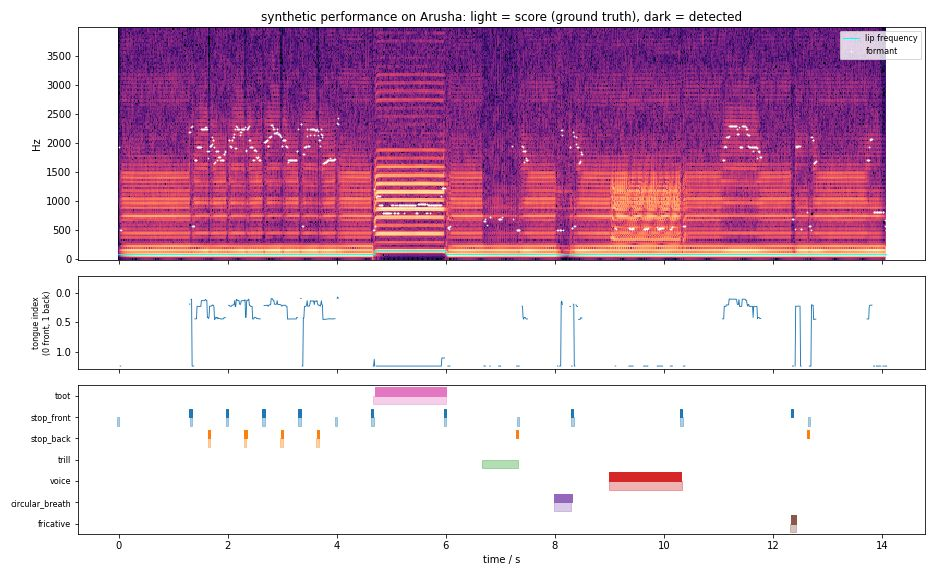

In [6]:
ROWS = ["toot", "stop_front", "stop_back", "trill", "voice", "circular_breath", "fricative"]

def cls(label):
    """Common class name for detections and ground-truth gestures."""
    if label.startswith("toot"):
        return "toot"
    if label in ("t", "d"):
        return "stop_front"
    if label in ("k", "g"):
        return "stop_back"
    return LABEL_MAP.get(label, label)

def plot_vs_truth(x, fa, segs, gestures=None, title="", fmax=4000):
    t, f, X = stft(x, FS, n_fft=4096, win=2048, hop=480)
    S = 20 * np.log10(X + 1e-9); S -= S.max()
    m = f < fmax
    fig, axs = plt.subplots(3, 1, figsize=(13, 8), sharex=True,
                            gridspec_kw={"height_ratios": [2.5, 1, 1.6]})
    axs[0].pcolormesh(t[::2], f[m][::2], S[::2, m][:, ::2].T, vmin=-75, vmax=0, shading="auto", cmap="magma",
                      rasterized=True)
    axs[0].plot(fa.t, fa.f0, color="cyan", lw=1, label="lip frequency")
    axs[0].plot(fa.t, fa.formant_hz, ".", color="white", ms=1.5, label="formant")
    axs[0].set_ylabel("Hz"); axs[0].set_title(title); axs[0].legend(loc="upper right", fontsize=8)
    axs[1].plot(fa.t, fa.tongue_index, lw=0.9)
    axs[1].set_ylim(1.3, -0.3); axs[1].set_ylabel("tongue index\n(0 front, 1 back)", fontsize=8)
    for lab, a, (lo, hi) in [("truth", 0.35, (0.0, 0.4)), ("detected", 1.0, (-0.4, 0.0))]:
        items = gestures if lab == "truth" else [(s.start, s.end, s.label) for s in segs]
        for s, e, l in items or []:
            c = cls(l)
            if c in ROWS:
                y0 = ROWS.index(c)
                axs[2].broken_barh([(s, max(e - s, 0.03))], (y0 + lo, hi - lo), color=COLORS[c], alpha=a)
    axs[2].set_yticks(range(len(ROWS))); axs[2].set_yticklabels(ROWS, fontsize=8)
    axs[2].set_ylim(len(ROWS) - 0.5, -0.5); axs[2].set_xlabel("time / s")
    plt.tight_layout(); show_jpeg(fig)

plot_vs_truth(y, fa, segs, controls.gestures,
              "synthetic performance on Arusha: light = score (ground truth), dark = detected")

In the spectrogram you see the lip frequency (cyan) jump to the 2nd resonance during the toot, and the
formant (white dots) move up for `ee` and down for `oo`. The table compares the detections with the score,
using the same matching rules as the evaluation (section 2.5):

In [7]:
norm = [Segment(s.start, s.end, cls(s.label)) for s in segs]
ev = evaluate_events([{"gestures": controls.gestures}], [norm])
rows = [{"technique": k, "true events": v["n_true"], "detected": v["n_pred"], "precision": v["precision"],
         "recall": v["recall"], "F1": v["f1"]} for k, v in ev.items() if k != "stop_place"]
print("Detector used:", "trained model" if used_model else "rule-based fallback")
pl = ev["stop_place"]
print(f"place of articulation (t/d vs k/g) of the {pl['n']} detected stops that match a true stop: "
      f"accuracy {pl['accuracy']:.2f}")
pd.DataFrame(rows).set_index("technique").round(2)

Detector used: trained model
place of articulation (t/d vs k/g) of the 14 detected stops that match a true stop: accuracy 0.86


,true events,detected,precision,recall,F1
technique,,,,,
stop,16,15,0.93,0.88,0.9
trill,1,0,0.00,0.00,0.0
voice,1,1,1.00,1.00,1.0
circular_breath,1,1,1.00,1.00,1.0
fricative,1,1,1.00,1.00,1.0
toot,1,1,1.00,1.00,1.0


The lip tracker finds the toot with either detector, because it does not need any learning; the sung note
(vocalisation) is also easy. The **rule-based fallback** is crude. It finds only the deepest dips and misses most
of the shallow tongue stops, it misses the trill and the fricative, and its circular-breathing rule fires
whenever the inverted vocal tract looks "sealed", so it reports many false circular breaths. The **trained
model** is far better (see 3.5). If the output above says "rule-based fallback", train the model with
`python scripts/synth/train_detector.py` and run this notebook again.

### 3.3 From formant to tongue index

The tongue index of section 2.2 relies on the model curve $F_{\text{model}}(\tau)$ of the bore. Here it is for
Arusha: the formant falls from about 2.6 kHz (tongue front) to about 1.1 kHz (tongue back).

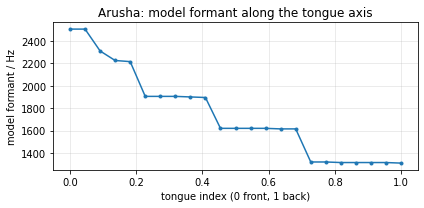

formant range of the model: 1310 .. 2505 Hz


In [8]:
tps, Fc = tongue_curve(bore)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot((tps - 0.4) / 0.55, Fc, "o-", ms=3)
ax.set_xlabel("tongue index (0 front, 1 back)"); ax.set_ylabel("model formant / Hz")
ax.set_title("Arusha: model formant along the tongue axis"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"formant range of the model: {Fc.min():.0f} .. {Fc.max():.0f} Hz")

### 3.4 A real recording: Tamaki1

Now a real performance from the Didge Archive. We take 18 seconds (14–32 s) of `tamaki1-long`: a rhythmic
part, a toot passage at about 26–27.5 s and the start of the detached notes at the end. Here we use the
library's own `plot_transcription` (spectrogram with lip frequency and formant, level, tongue index, events).

In [9]:
ins = archive.get("Tamaki1", root)
bore_t = Bore(ins.geometry)
x_full, fs = load_audio(ins.samples["song"], FS)
T0, T1 = 14.0, 32.0
x = x_full[int(T0 * fs):int(T1 * fs)]
print(ins.samples["song"].split("/")[-1], f"{len(x_full) / fs:.1f} s, excerpt {T0:.0f}-{T1:.0f} s")
print("Tamaki1 resonances / Hz:", [round(r.freq, 1) for r in bore_t.resonances[:4]])

t0 = time.time()
fa_r, segs_r = transcribe(x, fs, bore_t)
print(f"transcribe took {time.time() - t0:.0f} s;",
      "detector used:", "trained model" if hasattr(fa_r, "proba") else "rule-based fallback")

tamaki1-long.wav 37.4 s, excerpt 14-32 s
Tamaki1 resonances / Hz: [76.6, 216.2, 300.5, 459.7]


transcribe took 7 s; detector used: trained model


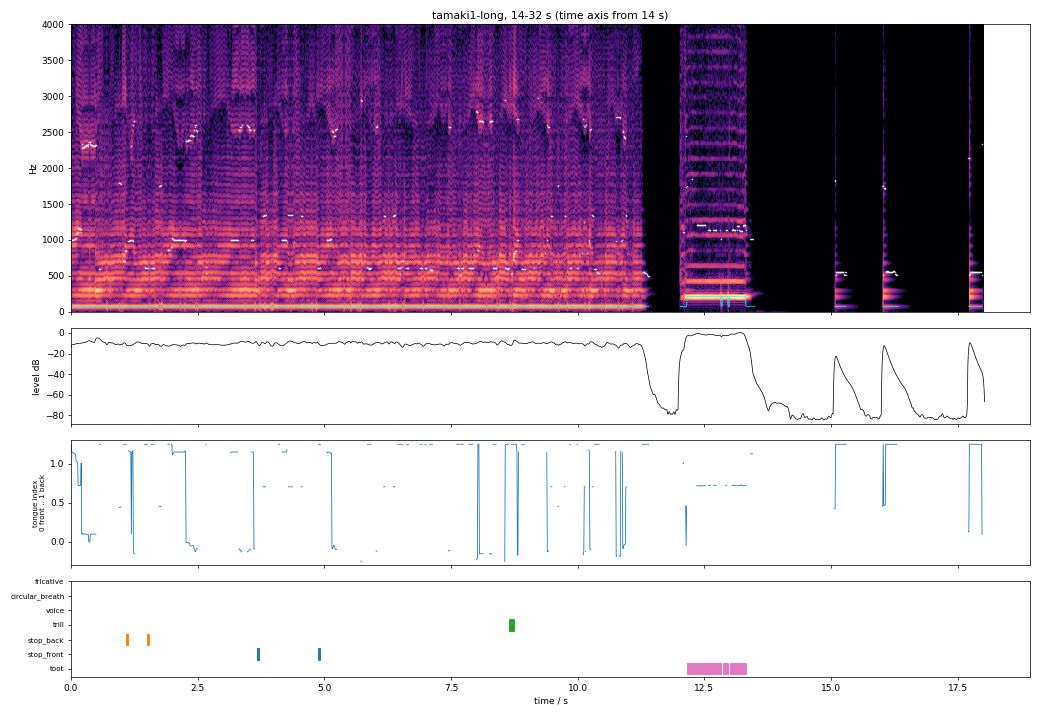

In [10]:
png = os.path.join(tempfile.mkdtemp(), "transcription.png")
plot_transcription(x, fs, fa_r, segs_r, png, title=f"tamaki1-long, {T0:.0f}-{T1:.0f} s (time axis from {T0:.0f} s)")
show_jpeg(png)

What the analysis says about this excerpt:

In [11]:
summ = summarize(fa_r, segs_r)
toots = [s for s in segs_r if s.label.startswith("toot")]
print(f"drone: {summ['drone_hz']:.1f} Hz (DidgeLab: {bore_t.drone:.1f} Hz)")
for s in toots:
    k = int(s.label[4:])
    fr = bore_t.resonances[k].freq
    print(f"toot at {T0 + s.start:.2f}-{T0 + s.end:.2f} s: {s.info['f0']:.1f} Hz, resonance {k + 1} "
          f"of DidgeLab at {fr:.1f} Hz ({1200 * np.log2(s.info['f0'] / fr):+.0f} cents)")
print("tongue front / middle / back share:", {k: round(v, 2) for k, v in summ["tongue"].items()})
print("events:", summ["events"])

drone: 76.6 Hz (DidgeLab: 76.6 Hz)
toot at 26.16-26.83 s: 213.1 Hz, resonance 2 of DidgeLab at 216.2 Hz (-25 cents)
toot at 26.86-26.97 s: 213.1 Hz, resonance 2 of DidgeLab at 216.2 Hz (-25 cents)
toot at 27.00-27.32 s: 212.5 Hz, resonance 2 of DidgeLab at 216.2 Hz (-30 cents)
tongue front / middle / back share: {'front': 0.22, 'middle': 0.03, 'back': 0.75}
events: {'stop_back': 2, 'stop_front': 2, 'trill': 1, 'toot1': 3}


The drone sits on the first DidgeLab resonance, and the toots on the second resonance, below it
(the archive toots are played 27–40 cents below the resonance, [synthesizer.md](../synthesizer.md) §7.2).
The formant (white dots) jumps between about 0.5–1 kHz and 2.3–2.7 kHz: in these recordings the rhythm is carried
mainly by fast formant changes. The front/back shares refer to this excerpt only. They differ from the
values for the whole recording (0.57 / 0.41, table in 3.6), because the formant is measured relative to the
median spectral envelope of the analysed audio (section 2.2), and the excerpt has a different median.

For comparison, the stored transcription of the whole recording (`doc/results/synth/transcriptions/`,
made by `scripts/synth/analyze_recordings.py` with the trained model) in the same time window:

In [12]:
stored = json.load(open(f"{RESULTS}/transcriptions/tamaki1-long.json"))
win = [s for s in stored["segments"] if T0 <= s["start"] < T1]
live = [(cls(s.label), T0 + s.start) for s in segs_r]
classes = sorted({cls(s["label"]) for s in win} | {c for c, _ in live})
pd.DataFrame({"stored (trained model, whole recording)": [sum(cls(s["label"]) == c for s in win) for c in classes],
              "this notebook": [sum(c == d for d, _ in live) for c in classes]}, index=classes)

,"stored (trained model, whole recording)",this notebook
stop_back,10,2
stop_front,0,2
toot,3,3
trill,0,1
voice,2,0


### 3.5 How good is the trained detector?

`scripts/synth/train_detector.py` trains the detector on 80 synthetic performances on random bores and
tests it on 32 synthetic performances (20 s each) on the eight Didge Archive geometries, which it never saw
during training. The stored result:

In [13]:
de = json.load(open(f"{RESULTS}/detector_eval.json"))
names = {"stop": "stop consonants (±60 ms)", "trill": "rolled-r trill", "voice": "vocalisation",
         "circular_breath": "circular breathing", "fricative": "fricatives / aspiration",
         "toot": "toots (lip tracker, no learning)"}
rows = [{"technique": names[k], "precision": v["precision"], "recall": v["recall"], "F1": v["f1"],
         "true events": v["n_true"], "detected": v["n_pred"]} for k, v in de["events"].items() if k in names]
tab = pd.DataFrame(rows).set_index("technique").round(3)
print(f"trained on {de['n_train']} performances, tested on {de['n_test']} on:", ", ".join(de["test_instruments"]))
print(f"place of articulation (t/d vs k/g) of detected stops: accuracy "
      f"{de['events']['stop_place']['accuracy']:.3f} ({de['events']['stop_place']['n']} stops)")
tab

trained on 80 performances, tested on 32 on: Arusha, Kizimkazi, Malveira, Matema, Nazare, Open Didgeridoo, Tamaki1, Tamaki2
place of articulation (t/d vs k/g) of detected stops: accuracy 0.987 (823 stops)


,precision,recall,F1,true events,detected
technique,,,,,
stop consonants (±60 ms),0.973,0.973,0.973,844,844
rolled-r trill,0.970,1.000,0.985,64,66
vocalisation,0.915,0.903,0.909,72,71
circular breathing,1.000,0.986,0.993,139,137
fricatives / aspiration,0.875,0.818,0.846,77,72
"toots (lip tracker, no learning)",0.985,1.000,0.993,67,68


In [14]:
pd.Series(de["frame_f1"], name="frame-level F1 (every 10 ms frame)").round(3).to_frame().T

,stop_front,stop_back,trill,voice,circular_breath,fricative
frame-level F1 (every 10 ms frame),0.9,0.902,0.969,0.913,0.969,0.809


These numbers measure how well the techniques **as the synthesizer plays them** can be recognised on unseen
instruments and recording conditions. They are an upper bound for real recordings.

### 3.6 What the players do in the archive recordings

Finally the stored summary of all songs and long recordings of the archive
(`doc/results/synth/recordings_summary.json`, from `scripts/synth/analyze_recordings.py`). `toot1` means a
toot on the 2nd resonance.

In [15]:
rs = pd.DataFrame(json.load(open(f"{RESULTS}/recordings_summary.json")))
rs["toots"] = rs["toots"].apply(lambda d: ", ".join(f"{k}: {v}" for k, v in d.items()) or "-")
rs["tongue front/back"] = rs["tongue"].apply(lambda d: f"{d['front']:.2f} / {d['back']:.2f}")
rs["formant median / Hz"] = rs["formant_p10_p50_p90_hz"].apply(lambda v: v[1])
rs[["recording", "duration_s", "drone_hz", "sim_drone_hz", "toots", "formant median / Hz", "tongue front/back",
    "tongue_moves_per_s", "voice_s", "stops_per_s", "trills", "circular_breaths"]].set_index("recording")

,duration_s,drone_hz,sim_drone_hz,toots,formant median / Hz,tongue front/back,tongue_moves_per_s,voice_s,stops_per_s,trills,circular_breaths
recording,,,,,,,,,,,
malveira-short-song,24.7,93.4,93.9,-,996,0.25 / 0.68,1.38,0.5,1.34,0,1
arusha-short-song,22.3,75.5,74.8,-,1951,0.53 / 0.31,1.88,2.1,0.27,0,0
nazare-short-song,19.4,74.7,74.9,-,1751,0.47 / 0.40,1.18,1.8,0.88,0,1
kizimkazi-short-song,26.4,76.1,74.7,-,1666,0.41 / 0.28,1.21,3.3,0.42,0,3
opendidge-short-song,19.8,74.7,74.1,-,2267,0.68 / 0.24,1.77,0.7,0.46,0,0
open-didge-drags,9.0,73.5,74.1,toot1: 1,1593,0.38 / 0.48,1.00,0.2,0.44,0,3
opendidge-2-straight-long,37.4,75.0,74.1,-,1347,0.41 / 0.52,2.03,30.6,0.13,0,0
tamaki1-long,37.4,76.6,76.8,toot1: 3,2291,0.57 / 0.41,1.87,2.6,0.37,0,1
tamaki-2-long,37.4,72.2,72.6,toot1: 1,2083,0.52 / 0.45,2.35,0.0,0.35,0,0


How to read this (see [synthesizer.md](../synthesizer.md) §9):

* **Drone**: every recording is played on the first DidgeLab resonance.
* **Toots** appear only in Tamaki1, Tamaki2 and Matema (plus one in `open-didge-drags`), on the 2nd resonance.
* **Tongue front/back** is the dominant technique: the formant moves between about 1 kHz and 3 kHz, 1–2.4
  times per second.
* **Vocalisation** is used throughout `opendidge-2-straight-long` (31 of 37 s), elsewhere only occasionally.
* **No rolled-r trills** survive the plausibility check.
* **Stops and circular breaths** are uncertain: real tongue stops are subtler than in the model. Read these
  columns as hypotheses until the recordings are annotated by hand.